# Section IV outputs

Running all cells in this notebook produces:

- **Tables I and II:** network configuration and relative energy results.
- **Figs. 4-6:** connected duration, connected energy, and RTT at 44 B for Normal, Robust, and Extreme coverage.
- **Fig. 8:** connected duration, connected energy, and RTT for 100 B, 500 B, and 1000 B under each coverage condition.
- **Fig. 9:** NB-IoT connected energy relative to LTE-M by operator, packet size, and coverage.

The generated figures are saved in `figures/` as PNG and PDF files. Generated table values are saved in `tables/`.


## 0. Settings, style and data

In [1]:
# ============================ SETTINGS ============================
from pathlib import Path

DATA_DIR  = Path("data")
FIG_DIR   = Path("figures")
TAB_DIR   = Path("tables")
SAVE      = True
FIG_FORMATS = ("png", "pdf")
DPI       = 600

FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

import re, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
print("pandas", pd.__version__, "| matplotlib", mpl.__version__, "| seaborn", sns.__version__)


pandas 3.0.5 | matplotlib 3.11.1 | seaborn 0.13.2


In [2]:
# ---------------------------------------------------------------
# Labels, orders and colours used in every figure of the paper
# ---------------------------------------------------------------
OP_ORDER  = ["OPNo1", "OPNo2", "OPSw1", "OPSw2", "OPSw3"]
OP_TEX    = {"OPNo1": r"$\mathrm{OP}_{1}^{\mathrm{No}}$", "OPNo2": r"$\mathrm{OP}_{2}^{\mathrm{No}}$",
             "OPSw1": r"$\mathrm{OP}_{1}^{\mathrm{Sw}}$", "OPSw2": r"$\mathrm{OP}_{2}^{\mathrm{Sw}}$",
             "OPSw3": r"$\mathrm{OP}_{3}^{\mathrm{Sw}}$"}
OP_TEX_ORDER = [OP_TEX[o] for o in OP_ORDER]
RAT_ORDER = ["NB-IoT", "LTE-M"]
COV_ORDER = ["Normal", "Robust", "Extreme"]
PAYLOADS  = [44, 100, 500, 1000]
RAT_PALETTE = ["#8dd3c7", "#fb8072"]          # NB-IoT, LTE-M (Figs. 4-6, 10)

def save(fig, name, tight=True, pad_inches=None):
    """Save a figure as PNG (600 dpi) and PDF."""
    if not SAVE:
        return
    for fmt in FIG_FORMATS:
        kw = {"dpi": DPI}
        if tight:
            kw["bbox_inches"] = "tight"
            if pad_inches is not None:
                kw["pad_inches"] = pad_inches
        fig.savefig(FIG_DIR / f"{name}.{fmt}", **kw)

def save_table(df, name, latex=None):
    """Save a table as CSV and, when given, as a LaTeX tabular body."""
    if not SAVE:
        return
    df.to_csv(TAB_DIR / f"{name}.csv", index=False)
    if latex is not None:
        (TAB_DIR / f"{name}.tex").write_text(latex, encoding="utf-8")

def theme_seaborn(font_scale=1.4):
    """Seaborn style of the measurement figures (Figs. 4-10)."""
    mpl.rcParams.update(mpl.rcParamsDefault)
    sns.set_theme(style="whitegrid", font_scale=font_scale)

def frame_black(ax, lw=1.5):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(lw)

In [3]:
# Section IV: one row per UDP echo transaction after energy-outlier cleaning
ALL_DATA = pd.read_csv(DATA_DIR / "dataset.csv")
S4 = ALL_DATA[ALL_DATA["analysis_scope"] == "section4_main"].copy()
S4["Operator"] = S4["operator"].map(OP_TEX)

def n_campaigns(d):
    # Campaign IDs are numbered per country.
    return d.assign(country=d["operator"].str[2:4]).groupby("country")["campaign_id"].nunique().to_dict()

print(f"Combined file: {len(ALL_DATA):,} rows; Section IV main: {len(S4):,} transactions; "
      f"campaigns per country {n_campaigns(S4)}")
display(S4.groupby(["rat", "operator", "coverage"]).size().unstack()[COV_ORDER])


Combined file: 124,814 rows; Section IV main: 124,193 transactions; campaigns per country {'No': 14, 'Sw': 37}


coverage         Normal  Robust  Extreme
rat    operator                         
LTE-M  OPNo1       2910     981     5051
       OPNo2       3004     834     6109
       OPSw1       3415   11300    14350
       OPSw2       1969     819      619
       OPSw3       3963     360      758
NB-IoT OPNo1       2633    1795      606
       OPNo2       2583    1231     1371
       OPSw1       4672   16528    15421
       OPSw2      12368    6867     1676

In [4]:
def relative_energy(d, stat="median", decimals=None):
    """NB-IoT energy relative to LTE-M (%) per operator, coverage and payload.

    decimals : round the two medians (in J) before taking the ratio; Table II of the
               paper is computed from medians rounded to 0.01 J (decimals=2).
    """
    g = d.groupby(["operator", "rat", "coverage", "packet_size_B"])["connected_energy_J"].agg(stat).unstack("rat")
    if decimals is not None:
        g = g.round(decimals)
    return (100 * (g["NB-IoT"] - g["LTE-M"]) / g["LTE-M"]).dropna()

BOX_METRICS = [("a", "connected_duration_s", "Connected Duration (s)"),
               ("b", "connected_energy_J",   "Connected Energy (J)"),
               ("c", "rtt_s",                "RTT (s)")]

def box_figure(d, metric, ylabel, name, figsize=(8, 6), order=OP_TEX_ORDER, ylim=None,
               legend_loc="upper right", lw=2, tick_size=20, legend_size=18):
    """Boxplot per operator and technology (style of Figs. 4-6 and 10a-c).

    The layout is fixed with tight_layout() before the y-limits are applied, as in
    the code that produced the published figures (this sets the left margin of the
    RTT panels).
    """
    theme_seaborn(1.4)
    fig, ax = plt.subplots(figsize=figsize)
    sns.boxplot(data=d, x="Operator", y=metric, hue="rat", order=order, hue_order=RAT_ORDER,
                palette=RAT_PALETTE, linewidth=lw, ax=ax)
    ax.set_ylabel(ylabel, fontsize=22); ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=tick_size); ax.tick_params(axis="y", labelsize=tick_size)
    ax.legend(title=None, fontsize=legend_size, loc=legend_loc)
    ax.grid(True, axis="y", linestyle="--", alpha=0.4)
    frame_black(ax)
    plt.tight_layout()
    if ylim:
        ax.set_ylim(*ylim)
    save(fig, name, tight=False); plt.show()

print("helper functions ready")


helper functions ready


## 1. Table I — Network configuration parameters

Observed/inferred from the power traces and the modem's `AT+QCSCON` indications; the OPNo1 values were confirmed by the operator. The timer is the configured value; the measured windows are in Table IV.

In [5]:
TABLE_I = pd.DataFrame([
    ("OPNo1", "NB-IoT", 5, "No"),  ("OPNo1", "LTE-M", 4, "Yes"),
    ("OPNo2", "NB-IoT", 10, "Yes"), ("OPNo2", "LTE-M", 5, "Yes"),
    ("OPSw1", "NB-IoT", 5, "No"),  ("OPSw1", "LTE-M", 10, "Yes"),
    ("OPSw2", "NB-IoT", 5, "No"),  ("OPSw2", "LTE-M", 4, "Yes"),
    ("OPSw3", "LTE-M", 10, "Yes")],
    columns=["Operator", "Radio interface", "Inactivity timer (s)", "cDRX activation"])
display(TABLE_I)
save_table(TABLE_I, "table1_configuration")

,Operator,Radio interface,Inactivity timer (s),cDRX activation
0,OPNo1,NB-IoT,5,No
1,OPNo1,LTE-M,4,Yes
2,OPNo2,NB-IoT,10,Yes
3,OPNo2,LTE-M,5,Yes
4,OPSw1,NB-IoT,5,No
5,OPSw1,LTE-M,10,Yes
6,OPSw2,NB-IoT,5,No
7,OPSw2,LTE-M,4,Yes
8,OPSw3,LTE-M,10,Yes


## 2. Table II — Median Connected-state energy of NB-IoT relative to LTE-M (44 B)

$100\,(\tilde E_{\text{NB-IoT}} - \tilde E_{\text{LTE-M}})/\tilde E_{\text{LTE-M}}$ with $\tilde E$ the median Connected-state energy of the operator, technology and coverage class, rounded to 0.01 J as in the paper.


In [6]:
REL = relative_energy(S4, decimals=2)
TABLE_II = (REL.xs(44, level="packet_size_B").unstack("coverage")[COV_ORDER]
            .reindex(["OPNo1", "OPNo2", "OPSw1", "OPSw2"]).round(1))
display(TABLE_II.apply(lambda col: col.map(lambda v: f"{v:+.1f}%")))

tex = "\n".join(f"{OP_TEX[op]} & " + " & ".join(f"${v:+.1f}\\%$" for v in row) + r" \\"
                for op, row in TABLE_II.iterrows())
save_table(TABLE_II.reset_index(), "table2_relative_energy_44B", latex=tex)

coverage,Normal,Robust,Extreme
operator,,,
OPNo1,+51.6%,+102.6%,+246.2%
OPNo2,+190.5%,+301.9%,+344.9%
OPSw1,-46.1%,+16.9%,+65.1%
OPSw2,+50.0%,+49.0%,+240.4%


## 3. Figs. 4, 5 and 6 — 44-byte transactions under normal, robust and extreme coverage

Panels: (a) Connected-state duration, (b) Connected-state energy, (c) RTT.


Fig. 4 - Normal coverage (28,384 transactions); RTT above 9 s (outside panel c): {('OPNo2', 'NB-IoT'): 2, ('OPSw2', 'NB-IoT'): 9}


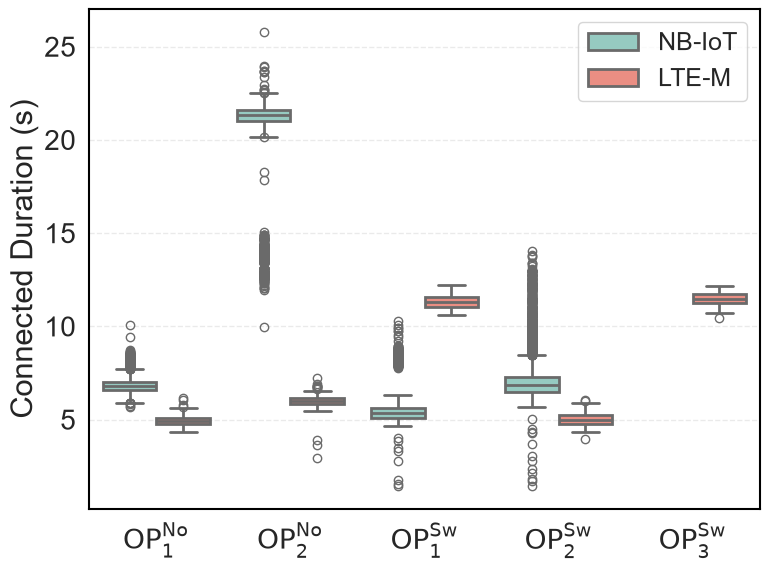

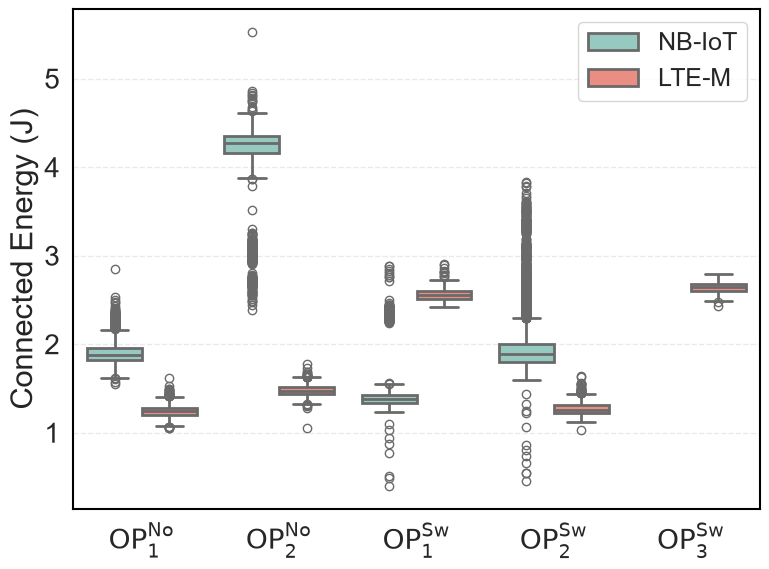

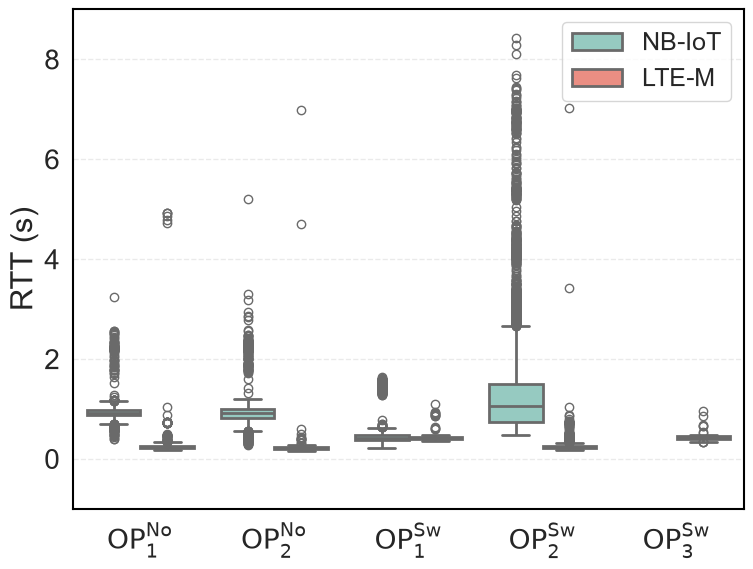

Fig. 5 - Robust coverage (16,217 transactions); RTT above 12 s (outside panel c): {('OPNo1', 'NB-IoT'): 7, ('OPNo2', 'LTE-M'): 1, ('OPSw2', 'NB-IoT'): 3}


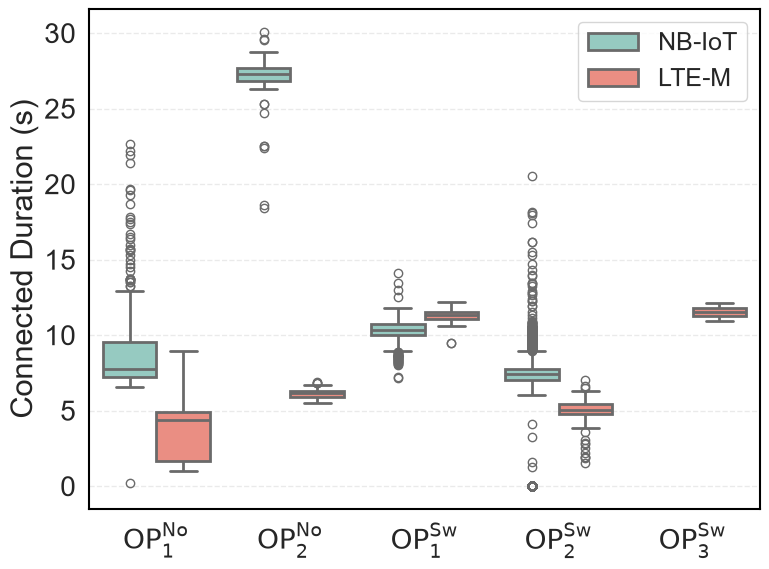

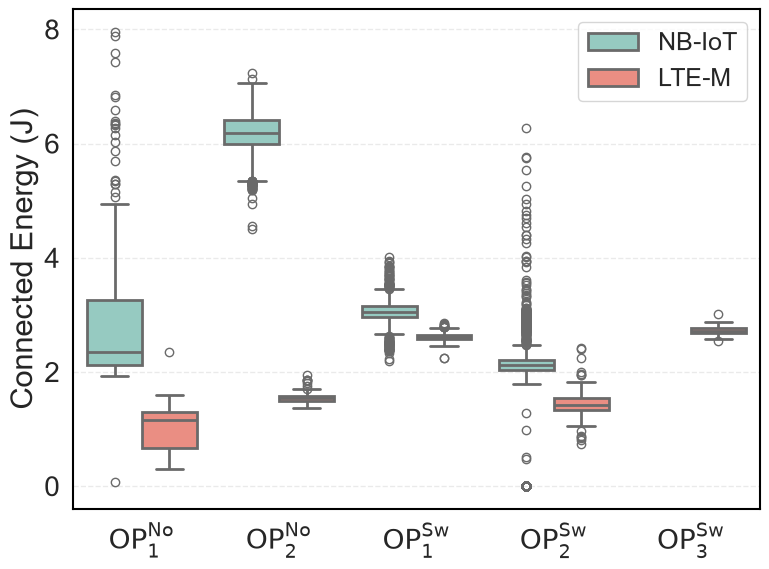

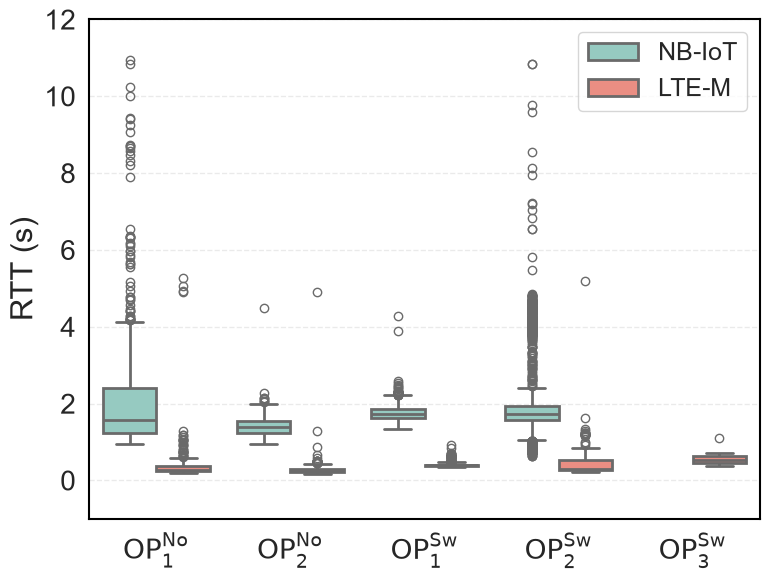

Fig. 6 - Extreme coverage (19,123 transactions); RTT above 45 s (outside panel c): {('OPSw2', 'NB-IoT'): 2}


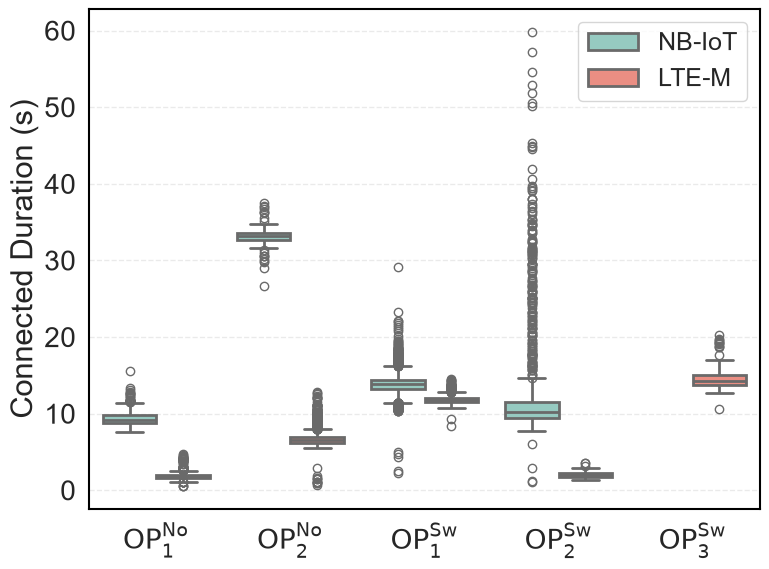

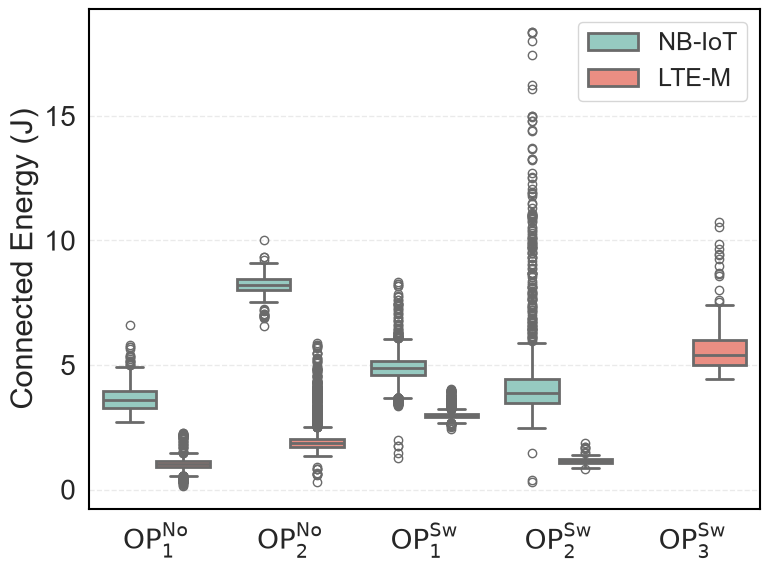

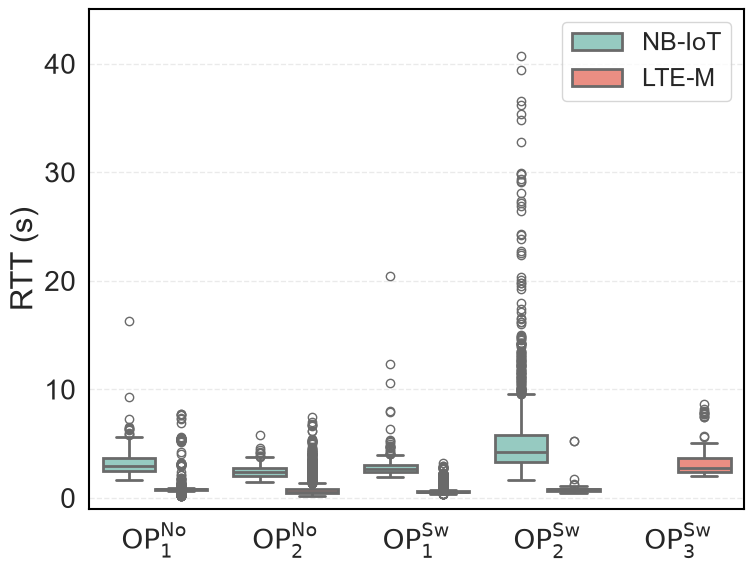

In [7]:
FIG_OF_COV = {"Normal": 4, "Robust": 5, "Extreme": 6}

# The RTT axes of the paper are limited to these ranges; transactions above the
# upper limit stay in the statistics but fall outside the view (counted below).
RTT_YLIM = {"Normal": (-1, 9), "Robust": (-1, 12), "Extreme": (-1, 45)}

d44 = S4[S4.packet_size_B == 44]
for cov in COV_ORDER:
    n = FIG_OF_COV[cov]
    dc = d44[d44.coverage == cov]
    above = dc[dc.rtt_s > RTT_YLIM[cov][1]].groupby(["operator", "rat"]).size()
    print(f"Fig. {n} - {cov} coverage ({len(dc):,} transactions); "
          f"RTT above {RTT_YLIM[cov][1]} s (outside panel c): {above.to_dict() if len(above) else 'none'}")
    for panel, metric, ylabel in BOX_METRICS:
        box_figure(dc, metric, ylabel, f"fig{n}{panel}_{metric}_{cov.lower()}_44B",
                   ylim=RTT_YLIM[cov] if metric == "rtt_s" else None)

## 4. Fig. 8


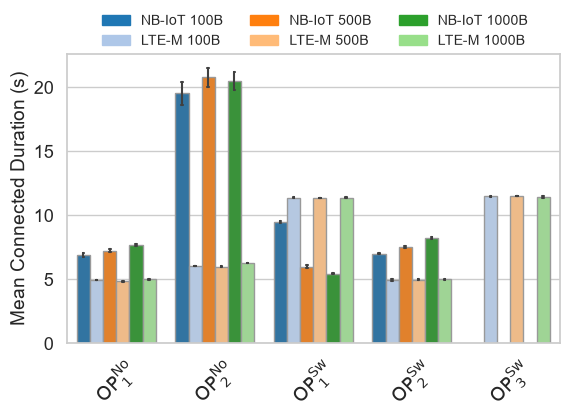

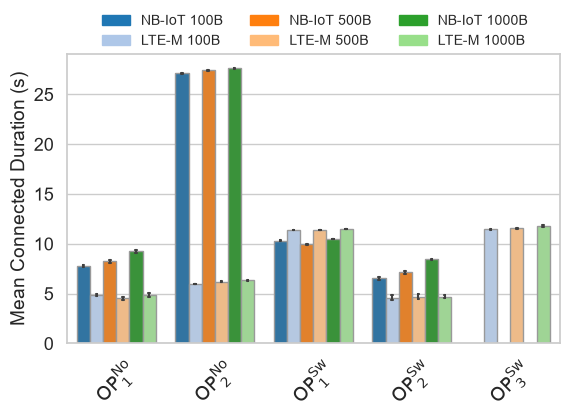

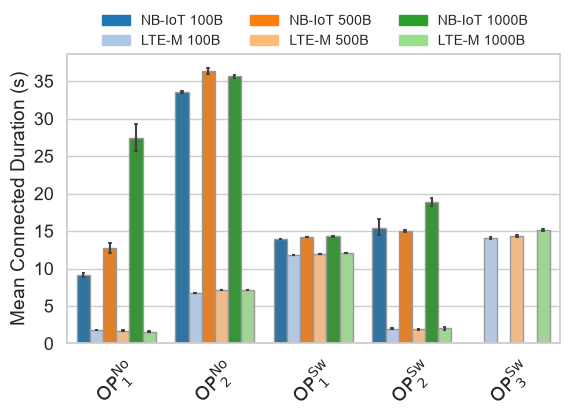

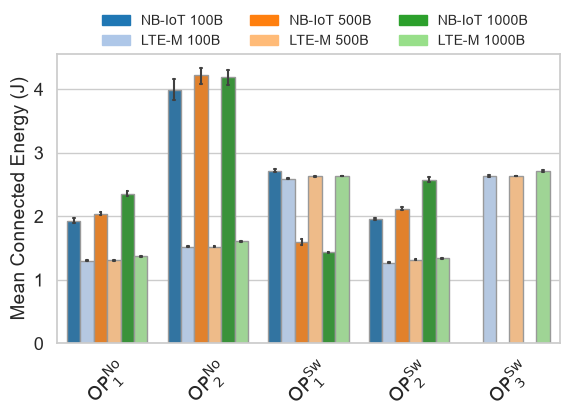

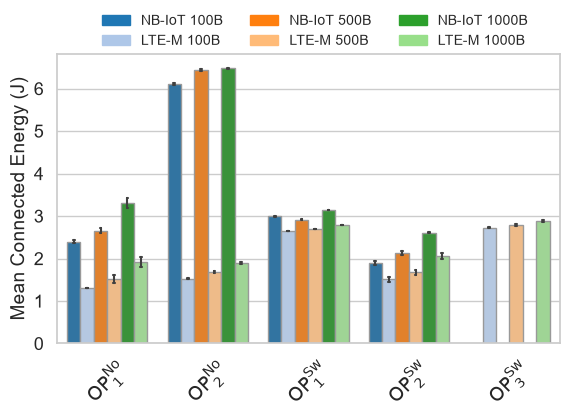

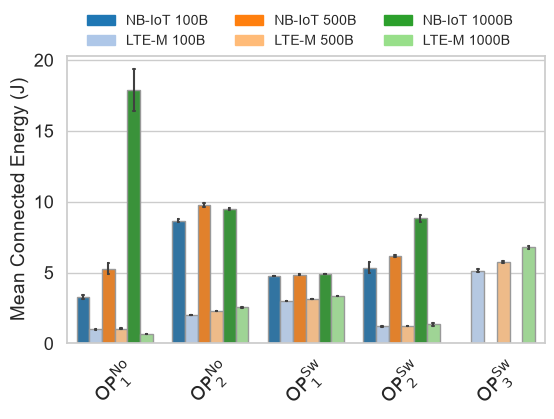

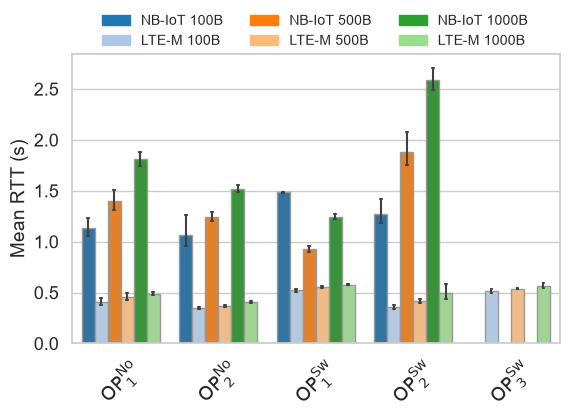

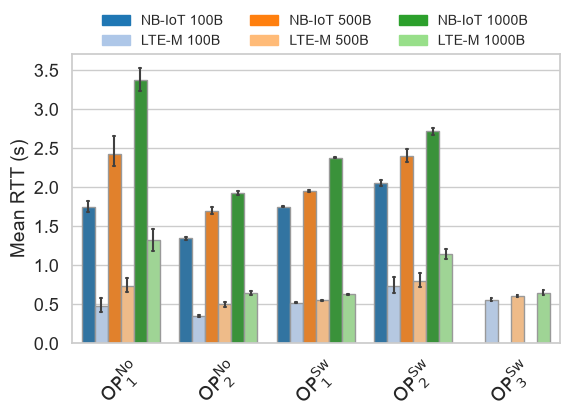

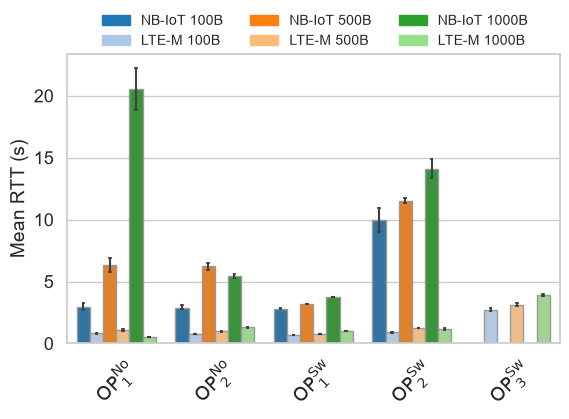

In [8]:
d8 = S4[S4.packet_size_B.isin([100, 500, 1000])].copy()
d8["Tech & Pkt Size"] = d8["rat"] + " " + d8["packet_size_B"].astype(str) + "B"
HUE8 = ["NB-IoT 100B", "LTE-M 100B", "NB-IoT 500B", "LTE-M 500B", "NB-IoT 1000B", "LTE-M 1000B"]
PAL8 = dict(zip(HUE8, sns.color_palette("tab20", n_colors=len(HUE8))))
METRICS8 = [("connected_duration_s", "Mean Connected Duration (s)"),
            ("connected_energy_J",   "Mean Connected Energy (J)"),
            ("rtt_s",                "Mean RTT (s)")]

panel = iter("abcdefghi")
for metric, ylabel in METRICS8:
    for cov in COV_ORDER:
        p = next(panel)
        theme_seaborn(1.4)
        fig = plt.figure(figsize=(6, 4.5)); ax = fig.add_subplot(111)
        sns.barplot(data=d8[d8.coverage == cov], x="Operator", y=metric, hue="Tech & Pkt Size",
                    order=OP_TEX_ORDER, hue_order=HUE8, palette=PAL8, edgecolor=".6",
                    errorbar=("ci", 95), capsize=0.10,
                    err_kws={"color": ".25", "linewidth": 1.5}, seed=0, ax=ax)
        ax.set_xlabel(""); ax.set_ylabel(ylabel, fontsize=14)
        ax.tick_params(axis="x", rotation=45, labelsize=14); ax.tick_params(axis="y", labelsize=13)
        if ax.get_legend() is not None:
            ax.get_legend().remove()
        fig.legend(handles=[Patch(color=PAL8[h], label=h) for h in HUE8], loc="upper center",
                   bbox_to_anchor=(0.55, 1.00991), ncol=3, frameon=False, fontsize=10)
        plt.tight_layout(rect=[0, 0.05, 1, 0.95])
        save(fig, f"fig8{p}_{metric}_{cov.lower()}"); plt.show()


## 5. Fig. 9


OPSw1, 100 B, normal coverage - LTE-M median RSRP -84 dBm, window +-10 dB


episodes  rsrp_min  rsrp_max  median_energy_J   used
rat    campaign_id                                                      
LTE-M  2526              179     -85.0     -83.0            2.516   True
NB-IoT 2524              177     -82.0     -78.0            1.291   True
       2534               50    -112.0    -112.0            2.859  False
       2536              215    -112.0    -111.0            2.799  False

all transactions (main campaigns): +8.5 %   ->   matched RSRP: NB-IoT 1.291 J vs LTE-M 2.516 J = -48.7 %


coverage                Normal  Robust  Extreme
operator packet_size_B                         
OPNo1    100              44.0    79.0    208.0
         500              54.0    83.0    456.0
         1000             77.0   111.0   2129.0
OPNo2    100             183.0   300.0    344.0
         500             193.0   285.0    327.0
         1000            177.0   250.0    282.0
OPSw1    100             -49.0    14.0     61.0
         500             -46.0    12.0     56.0
         1000            -46.0    13.0     57.0
OPSw2    100              52.0    47.0    211.0
         500              57.0    42.0    394.0
         1000             87.0    36.0    555.0

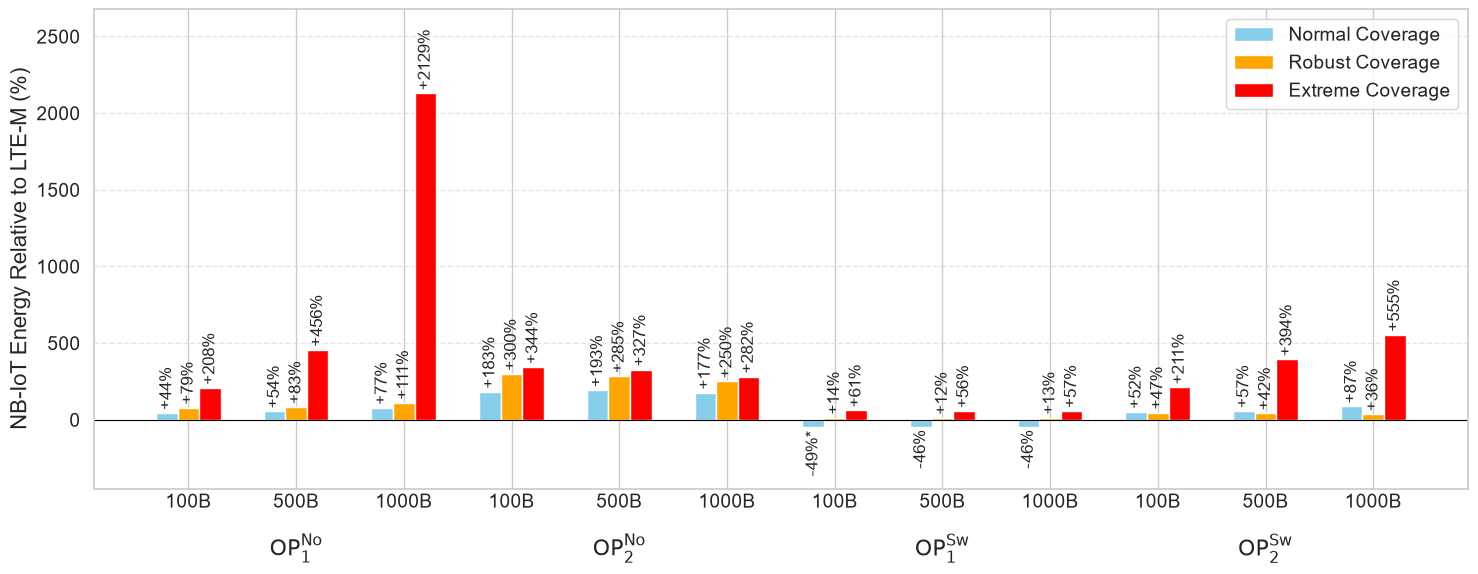

In [11]:
REL = relative_energy(S4)          # same definition as Table II
FIG9 = (REL.reset_index(name="EnergyDiff")
           .query("packet_size_B in [100, 500, 1000] and operator in ['OPNo1','OPNo2','OPSw1','OPSw2']")
           .reset_index(drop=True))
FIG9["method"] = "median, all transactions"

# ---------------- OPSw1, 100 B, normal coverage: matched RSRP ----------------
MATCH_CELL = ("OPSw1", 100, "Normal")
MATCH_WINDOW_DB = 10          # both technologies within +-10 dB of the LTE-M median RSRP
MARK_MATCHED_CELL = True      # append * to the bar label

SUP = (ALL_DATA[ALL_DATA["analysis_scope"] == "fig9_only"].copy()
       .rename(columns={"rsrp_dBm": "rsrp",
                        "connected_energy_J": "E_conn TOTAL (J)"}))
ref_rsrp = SUP.loc[SUP.rat == "LTE-M", "rsrp"].median()
SUP["in_window"] = (SUP["rsrp"] - ref_rsrp).abs() <= MATCH_WINDOW_DB
print(f"OPSw1, 100 B, normal coverage - LTE-M median RSRP {ref_rsrp:.0f} dBm, window +-{MATCH_WINDOW_DB} dB")
display(SUP.groupby(["rat", "campaign_id"]).agg(
    episodes=("rsrp", "size"), rsrp_min=("rsrp", "min"), rsrp_max=("rsrp", "max"),
    median_energy_J=("E_conn TOTAL (J)", "median"), used=("in_window", "all")).round(3))

W = SUP[SUP.in_window]
e_nb = W.loc[W.rat == "NB-IoT", "E_conn TOTAL (J)"].median()
e_lt = W.loc[W.rat == "LTE-M", "E_conn TOTAL (J)"].median()
matched = 100 * (e_nb / e_lt - 1)
cell = (FIG9.operator == MATCH_CELL[0]) & (FIG9.packet_size_B == MATCH_CELL[1]) & (FIG9.coverage == MATCH_CELL[2])
print(f"all transactions (main campaigns): {FIG9.loc[cell, 'EnergyDiff'].iloc[0]:+.1f} %   ->   "
      f"matched RSRP: NB-IoT {e_nb:.3f} J vs LTE-M {e_lt:.3f} J = {matched:+.1f} %")
FIG9.loc[cell, "EnergyDiff"] = matched
FIG9.loc[cell, "method"] = f"median, RSRP within {MATCH_WINDOW_DB} dB of LTE-M (episode level)"

FIG9["EnergyDiff"] = FIG9["EnergyDiff"].round(0)
display(FIG9.pivot_table(index=["operator", "packet_size_B"], columns="coverage", values="EnergyDiff")[COV_ORDER])
save_table(FIG9, "fig9_relative_energy_values")

theme_seaborn(1.4)
mpl.rcParams.update({"font.size": 14, "axes.titlesize": 16, "axes.labelsize": 16,
                     "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14})
COV_LABEL  = {"Normal": "Normal Coverage", "Robust": "Robust Coverage", "Extreme": "Extreme Coverage"}
COV_COLOR  = {"Normal": "skyblue", "Robust": "orange", "Extreme": "red"}
width = 0.2
COV_OFFSET = {"Normal": -width, "Robust": 0, "Extreme": width}

fig, ax = plt.subplots(figsize=(15, 6))
x_pos, pkt_labels, centers, op_labels = [], [], [], []
index = 0
for op in ["OPNo1", "OPNo2", "OPSw1", "OPSw2"]:
    start = index
    for B in [100, 500, 1000]:
        for cov in COV_ORDER:
            val = FIG9[(FIG9.operator == op) & (FIG9.packet_size_B == B) & (FIG9.coverage == cov)]["EnergyDiff"].iloc[0]
            bx = index + COV_OFFSET[cov]
            ax.bar(bx, val, width=width, color=COV_COLOR[cov], label=COV_LABEL[cov] if index == 0 else "")
            star = "*" if (MARK_MATCHED_CELL and (op, B, cov) == MATCH_CELL) else ""
            ax.text(bx, val + 20 if val >= 0 else val - 20, f"{val:+.0f}%{star}", ha="center",
                    va="bottom" if val >= 0 else "top", fontsize=12, rotation=90)
        x_pos.append(index); pkt_labels.append(f"{B}B"); index += 1
    centers.append((start + index - 1) / 2); op_labels.append(OP_TEX[op])

ax.set_xticks(x_pos); ax.set_xticklabels(pkt_labels, fontsize=14)
vmax, vmin = FIG9.EnergyDiff.max(), FIG9.EnergyDiff.min()
for c, lab in zip(centers, op_labels):
    ax.text(c, -vmax * 0.35, lab, ha="center", va="top", fontsize=16)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("NB-IoT Energy Relative to LTE-M (%)", fontsize=16)
ax.set_ylim(bottom=vmin - 400, top=vmax + 550)
ax.legend(title="", fontsize=14)
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
ax.tick_params(axis="x", which="both", length=0)
plt.subplots_adjust(bottom=0.6)   # as in the original code: tight_layout() starts from this geometry
plt.tight_layout(); save(fig, "fig9_relative_energy_by_packet_size"); plt.show()


## 6. Files written


In [10]:
for folder in [FIG_DIR, TAB_DIR]:
    files = sorted(p.name for p in folder.iterdir() if p.is_file())
    print(f"{folder}/  ({len(files)} files)")
    for f in files:
        print("   ", f)

figures/  (38 files)
    fig4a_connected_duration_s_normal_44B.pdf
    fig4a_connected_duration_s_normal_44B.png
    fig4b_connected_energy_J_normal_44B.pdf
    fig4b_connected_energy_J_normal_44B.png
    fig4c_rtt_s_normal_44B.pdf
    fig4c_rtt_s_normal_44B.png
    fig5a_connected_duration_s_robust_44B.pdf
    fig5a_connected_duration_s_robust_44B.png
    fig5b_connected_energy_J_robust_44B.pdf
    fig5b_connected_energy_J_robust_44B.png
    fig5c_rtt_s_robust_44B.pdf
    fig5c_rtt_s_robust_44B.png
    fig6a_connected_duration_s_extreme_44B.pdf
    fig6a_connected_duration_s_extreme_44B.png
    fig6b_connected_energy_J_extreme_44B.pdf
    fig6b_connected_energy_J_extreme_44B.png
    fig6c_rtt_s_extreme_44B.pdf
    fig6c_rtt_s_extreme_44B.png
    fig8a_connected_duration_s_normal.pdf
    fig8a_connected_duration_s_normal.png
    fig8b_connected_duration_s_robust.pdf
    fig8b_connected_duration_s_robust.png
    fig8c_connected_duration_s_extreme.pdf
    fig8c_connected_duration_s_extre